## Please run these cells IN ORDER first! This ensures variables established in earlier cells can be used in later cell functions.
I separated this assignment into multiple code cells to make it easier to digest. There are also some MarkDown cells to answer questions needing a written response.
MarkDown cells for questions from HW5 have been removed, since they added clutter and didn't impact the code.

In [3]:
"""
This list of dictionaries was copied exactly as-is from the assignment instructions.
"""

from datetime import date, datetime

RAW_INSPECTIONS = [

{"hive_id": "H-01", "inspection_date": "2026-08-01", "temp_f": 84,

"weight_lb": "142.5", "mites": 3, "queen_seen": True, "notes": "calm"},

{"hive_id": "H-01", "inspection_date": "2026-08-15", "temp_f": "89",

"weight_lb": "137.0", "mites": "8", "queen_seen": False, "notes": "queen not found"},

{"hive_id": "H-01", "inspection_date": "2026-08-15", "temp_f": "89",

"weight_lb": "137.0", "mites": "8", "queen_seen": False, "notes": "queen not found"},

{"hive_id": "h-02", "inspection_date": "2026-08-02", "temp_f": "85F",

"weight_lb": 155.2, "mites": 2, "queen_seen": "yes", "notes": None},

{"hive_id": "H-02", "inspection_date": "08/16/2026", "temp_f": 91,

"weight_lb": " 151.4 ", "mites": 5, "queen_seen": True, "notes": ""},

{"hive_id": "H-02", "inspection_date": "2026-08-32", "temp_f": 92,

"weight_lb": 149.8, "mites": 6, "queen_seen": False, "notes": "bad date"},

{"hive_id": "H-03", "inspection_date": "2026-08-03", "temp_f": None,

"weight_lb": 130.0, "mites": 0, "queen_seen": True, "notes": "cool morning"},

{"hive_id": "H-03", "inspection_date": "2026-08-17", "temp_f": 96,

"weight_lb": None, "mites": 9, "queen_seen": "no", "notes": "light hive"},

{"hive_id": "H-04", "inspection_date": "2026-08-04", "temp_f": 79,

"weight_lb": 160.0, "mites": -1, "queen_seen": True, "notes": "counter reset"},

{"hive_id": "H-04", "inspection_date": "2026-08-18", "temp_f": 81,

"weight_lb": 158.5, "mites": 4, "queen_seen": True, "notes": "calm"},

{"hive_id": " H-05 ", "inspection_date": "2026-08-05", "temp_f": "72",

"weight_lb": "bad", "mites": 1, "queen_seen": True, "notes": "scale failed"},

{"hive_id": "H-05", "inspection_date": "2026-08-19", "temp_f": 74,

"weight_lb": 144.2, "mites": 3, "queen_seen": True, "notes": "retest"},

{"hive_id": "H-06", "inspection_date": "2026-08-06", "temp_f": 101,

"weight_lb": 120.0, "mites": 12, "queen_seen": False, "notes": "agitated"},

{"hive_id": "H-06", "inspection_date": "2026-08-20", "temp_f": 97,

"weight_lb": 109.4, "mites": 14, "queen_seen": False, "notes": "low stores"},

]

# This prints the length of the list of records, just so I know how many records there are.
print(f"The length of the original RAW_INSPECTIONS list is {len(RAW_INSPECTIONS)}.")

The length of the original RAW_INSPECTIONS list is 14.


In [4]:
# QUESTION 2: Normalize one record

# This makes a copy of the RAW_INSPECTIONS list of records before the normalization process starts.
raw_insp_copy = RAW_INSPECTIONS.copy()
# We use this at the end to make sure we didn't alter the original.

def valid_hive_id(value): # Helper function
    """
    Checks for H- followed by exactly two digits.
    
    ARGUMENTS:
    value: can be any type, but will return False if not a string.
    This is the Hive ID we're checking to see if it's properly formatted.

    RETURNS:
    True if the Hive ID is in proper format, False if not.
    """

    if not isinstance(value, str): # Checks if hive_id is a string. If not, returns False.
        return False

    hv_id = value.strip().upper() # Strips whitespace from hive_id string and makes it uppercase.

    if len(hv_id) != 4: # If hive_id isn't exactly 4 characters, returns False.
        return False

    if hv_id[0:2] != "H-": # If the first two characters aren't "H-", returns False.
        return False

    # If the last two characters aren't digits, returns False.
    if not hv_id[2].isdigit() or not hv_id[3].isdigit():
        return False

    return hv_id # Returns normalized hive_id if all criteria is met.


def parse_date(value): # Helper function
    """"
    Returns a datetime.date or None if the date is invalid.

    ARGUMENTS:
    value: can be any type. The date you are trying to convert to a datetime.date().

    RETURNS:
    value converted to a datetime.date or None if it's an invalid date.
    """

    # Gen AI was used to learn about the isinstance function, since I wanted to do
    # different things with different data types and wanted to see what could be used besides type.
    if isinstance(value, date): # Checks if the value is already a date, returns it if so.
        return value

    if not isinstance(value, str): # Checks if the value is a string, returns None if it isn't.
        return None

# This tries using YYYY-MM-DD or MM-DD-YYYY, with dashes (-) and slashes (/) to format the
# string into a datetime.date.
# If it succeeds, then it returns a datetime.date. If all attempts fail, returns None.
    for fmt in ["%m-%d-%Y", "%m/%d/%Y", "%Y-%m-%d", "%Y/%m/%d"]:
        # ERROR HANDLING: if we get a ValueError here, we just continue trying other formats.
        try:
            return datetime.strptime(value, fmt).date()
        # Used Gen AI to learn about ValueError.
        except ValueError:
            continue

    return None


def convert_bool(value): # Helper function
    """
    Converts yes/no queen_seen strings to booleans.
    
    ARGUMENTS:
    value: can be any type, but the function will return None if it's not a string or boolean.

    RETURNS:
    value converted into a boolean, or None if conversion fails.
    """

    if isinstance(value, bool): # Checks if value is already boolean. If so, returns it as-is.
        return value

    # Checks if the value is a string. If so, strips whitespaces and makes it lowercase.
    if isinstance(value, str):
        value = value.strip().lower()

        if value == "yes": # Changes "yes" str to True.
            return True

        if value == "no": # Changes "no" str to False.
            return False

    return None # Returns None if it doesn't return a boolean value with the above code.


def normalize_record(rec: dict) -> tuple[dict | None, str]: # This is the main function.
    """
    This function will take a record and normalize it.

    ARGUMENTS:
    rec: Must be DICTIONARY. It's the entry from the RAW_INSPECTIONS
    list of dictionaries that will be normalized.

    RETURNS:
    A TUPLE with two values. The first will be either a DICTIONARY containing the cleaned record
    or it will be empty (None) because the record was rejected. The second value will be a STRING
    that explains why the record was rejected if it was, or a blank string.
    """

    norm_record = {} # Establishes blank dictionary for the normalized record output.

    #1. Normalize hive_id by stripping whitespace and converting to uppercase.
    # Accepts only "H-" followed by 2 digits.
    h_id = rec.get("hive_id") # Gen AI was used to learn about get().

    norm_id = valid_hive_id(h_id) # Calls the valid_hive_id helper function from earlier.

    if norm_id is False:
        return (None, "invalid hive_id") # If hive_id is false, rejects for invalid hive id.

    norm_record["hive_id"] = norm_id # Sets norm_record to normalized hive id.

    #2 Parse inspection_date by accepting YYYY-MM-DD or MM-DD-YYYY and
    # storing as a datetime.date. Impossible dates are rejected.
    # Uses the parse_date helper function.
    inspection_date = parse_date(rec.get("inspection_date"))

    # If we failed to convert the date to a datetime.date, rejects for invalid date.
    if inspection_date is None:
        return (None, "invalid inspection_date")

    # Otherwise, sets norm_record to normalized date.
    norm_record["inspection_date"] = inspection_date

    #3 Normalize temp_f by removing the final "F" and converting to float.
    # None is fine. Reject values outside -20 thru 130.
    temp = rec.get("temp_f")

    if temp is None: # If there is no temp, sets norm_record temp to none.
        norm_record["temp_f"] = None
    else:
        try:
            if isinstance(temp, str): # If temp is a string, strips whitespaces.
                temp = temp.strip()

                if temp.upper().endswith("F"): # If temp ends with an F, removes it.
                    temp = temp[:-1].strip()

            temp = float(temp) # Tries to convert temp to a float.

        except (TypeError, ValueError):
            norm_record["temp_f"] = None # If conversion fails, sets temp to none.

        if temp < -20 or temp > 130:
            return (None, "temp_f out of range") # If temp is under -20 or over 130, rejects.

        norm_record["temp_f"] = temp # If checks are passed, sets norm_record to normalized temp.

    #4 Normalize weight_lb by converting to float. If this fails, store
    # None but don't reject. Do reject any negative weight.
    weight = rec.get("weight_lb")

    # ERROR HANDLING: if converting to float causes an error, we just set weight to None.
    try: # Tries to convert weight to a float.
        weight = float(weight)
    except (TypeError, ValueError):
        weight = None # If conversion doesn't work, sets weight to None.

    if weight is not None and weight < 0: # Rejects if weight is negative.
        return (None, "negative weight")

    norm_record["weight_lb"] = weight # Sets norm_record to normalized weight.

    #5 Normalize mites by converting to type int. Reject any negative values.
    mites = rec.get("mites")

    try: # Tries to convert mites to type int.
        mites = int(mites)
    except (TypeError, ValueError):
        return (None, "invalid mites") # If conversion doesn't work, rejects for invalid mites.

    if mites < 0:
        return (None, "negative mites") # If mites are negative, rejects for negative mites.

    norm_record["mites"] = mites # If checks pass, sets norm_record mites to normalized mites.

    #6 Normalize queen_seen by converting "yes" and "no" values to booleans.
    # If already a boolean, keep as-is. Reject any other value besides boolean and yes/no.
    # Uses convert_bool helper function from earlier.
    queen_seen = convert_bool(rec.get("queen_seen"))

    if queen_seen is None: # If convert_bool returned None, rejects for invalid queen_seen.
        return (None, "invalid queen_seen")

    # Otherwise, sets norm_record queen_seen to normalized boolean value.
    norm_record["queen_seen"] = queen_seen

    #7 Normalize notes by converting any missing notes to an ampty string.
    notes = rec.get("notes")

    if notes is None: # Converts notes to empty string if it's none.
        notes = ""

    norm_record["notes"] = notes # Sets norm_record notes to normalized notes value.

    # If it's not rejected earlier, this returns the normalized record
    # and an empty reason string.
    return (norm_record,"")

print(f"Normalized 1st record's dictionary: {normalize_record(RAW_INSPECTIONS[0])}.")
print(f"Normalized 6th record's rejection output,"
      f" impossible date: {normalize_record(RAW_INSPECTIONS[5])}")


# REQUIRED EVIDENCE

# This checks to see if the original dictionary has changed
# since it was copied before the function ran.
# I tested it by changing the original dictionary and it works.
# I have since removed the code that changed the dictionary,
# of course, since this assignment is supposed to keep it the same.
if raw_insp_copy == RAW_INSPECTIONS:
    print("REQUIRED EVIDENCE 1:\nThe original dictionary has not changed.")
else:
    print("The original dictionary was changed!")

Normalized 1st record's dictionary: ({'hive_id': 'H-01', 'inspection_date': datetime.date(2026, 8, 1), 'temp_f': 84.0, 'weight_lb': 142.5, 'mites': 3, 'queen_seen': True, 'notes': 'calm'}, '').
Normalized 6th record's rejection output, impossible date: (None, 'invalid inspection_date')
REQUIRED EVIDENCE 1:
The original dictionary has not changed.


In [5]:
# QUESTION 3: Clean the collection and keep an audit trail

def clean_records(records: list[dict]) -> tuple[list[dict], list[dict]]:
    """
    This function has normalize_record from the previous cell loop thru a whole list of records.

    ARGUMENTS:
    records: must be a LIST of DICTIONARIES. This is the list of records you are cleaning.

    RETURNS:
    A TUPLE with two lists. The first list is all cleaned records that
    were not rejected. The second list is all records that were rejected
    during the cleaning process.
    """
    cleaned = [] # Establishes blank list for normalized records
    rejected = [] # Blank list for rejected records.
    seen = [] # Blank list for records the function has "seen". Used to check for duplicates.

    # This uses enumerate to iterate thru the list of records, so we can access the index and value.
    for source_index, record in enumerate(records):
        #Gen AI was used to learn to use enumerate properly to access index and value.

        # Normalizes the record, assigns normalized record (index 0) to
        # "clean" and reason string (index 1) to "reason"
        clean = normalize_record(record)[0]
        reason = normalize_record(record)[1]

        # If normalization failed (i.e., clean is type None), adds to audit entry dictionary.
        if clean is None:
            audit_entry = {"source_index": source_index} # Adds source index first.

            # Adds hive_id second, if it is available.
            if "hive_id" in record:
                audit_entry["hive_id"] = record["hive_id"]

            audit_entry["reason"] = reason # Adds rejection reason third.

            # Adds the audit entry dictionary to the rejected list.
            rejected.append(audit_entry)
            # If it's rejected here, skips the remaining code
            # (checking for dupliates) since it's not needed.
            continue

        # Creates a key using hive_id and inspection_date to look for duplicates.
        key = (clean["hive_id"], clean["inspection_date"])

        # Checks for duplicates in the "seen" list. If it's in there,
        # adds the record to the rejected list.
        if key in seen:
            rejected.append({"source_index": source_index,
                "hive_id": clean["hive_id"],
                "reason": "duplicate inspection"})
            continue # If it's already in seen, skips the rest of
            # this code so it's not added a second time.

        # If the record is not a duplicate, we add it to the "seen" list and the "cleaned" list.
        seen.append(key)
        cleaned.append(clean)

    return (cleaned, rejected) # Returns tuple with list of cleaned and rejected records.


# This prints the total successes and rejections from the clean_records function.
print(f"For the original RAW_INSPECTIONS list, clean_records returns {len(clean_records(RAW_INSPECTIONS)[0])}"
       " successfully cleaned records and {len(clean_records(RAW_INSPECTIONS)[1])} rejections.\n")
print(f"The list of cleaned records is as follows: {clean_records(RAW_INSPECTIONS)[0]}.\n")
print(f"The list of rejections is as follows: {clean_records(RAW_INSPECTIONS)[1]}.\n")


def audit_counts(rejected: list[dict]) -> dict:
    """
    This goes through the rejections and creates a dictionary showing
    how many records were rejected for each reason.

    ARGUMENTS:
    rejected: must be LIST of DICTIONARIES. This is the list of rejected
    records from the clean_records function.

    RETURNS:
    a DICTIONARY showing rejection reasons as keys and the # of records
    rejected for each reason as values.
    """

    # This establishes a "counts" dictionary with every rejection reason. Values are set to 0 at the beginning.
    counts = {"invalid hive_id": 0, "invalid inspection_date": 0, "temp_f out of range": 0, "negative weight": 0,
              "invalid mites": 0, "negative mites": 0, "invalid queen_seen": 0, "duplicate inspection": 0}

    for rejection in rejected: # Iterates through each rejection in rejected list.
        reason = rejection["reason"] # Assigns the rejection reason str to the "reason" variable.

        counts[reason] += 1 # Adds one to the value for the rejection reason key.

    return counts # Returns the updated counts dictionary.

print(f"The output of audit_counts for the original RAW_INSPECTIONS list is: {audit_counts(clean_records(RAW_INSPECTIONS)[1])}.\n")

# Below are the 3 specific tests called for by the assignment.

# TEST 1
# Tests what happens if audit_counts has an empty input. All rejection counts are 0.
print(f"TEST 1: The output of function audit_counts with an empty input is: {audit_counts("")}.")

# TEST 2
# Tests what happens if audit counts has two duplicates (i.e., three of the same record).

# This establishes a list with three of the same record. So one is original, and two are duplicates.
TWO_DUPLICATES = [{"hive_id": "H-01", "inspection_date": "2026-08-01", "temp_f": 84,

"weight_lb": "142.5", "mites": 3, "queen_seen": True, "notes": "calm"},
{"hive_id": "H-01", "inspection_date": "2026-08-01", "temp_f": 84,

"weight_lb": "142.5", "mites": 3, "queen_seen": True, "notes": "calm"},
{"hive_id": "H-01", "inspection_date": "2026-08-01", "temp_f": 84,

"weight_lb": "142.5", "mites": 3, "queen_seen": True, "notes": "calm"}]

# The result is that the "duplicate inspection" reason has a count of 2, and everything else is a count of 0.
print(f"TEST 2: The output of function audit_counts with two duplicate records is: {audit_counts(clean_records(TWO_DUPLICATES)[1])}.")

#TEST 3
# Tests what happens if we use a collection where every record will be rejected.

# Establishes a list of 5 records where each is rejected for a different reason.
ALL_REJECTS = [{"hive_id": "X-01", "inspection_date": "2026-08-01", "temp_f": 84,

"weight_lb": "142.5", "mites": 3, "queen_seen": True, "notes": "calm"},

{"hive_id": "H-01", "inspection_date": "2026-67-89", "temp_f": "89",

"weight_lb": "137.0", "mites": "8", "queen_seen": False, "notes": "queen not found"},

{"hive_id": "H-01", "inspection_date": "2026-08-15", "temp_f": "89",

"weight_lb": "-137.0", "mites": "8", "queen_seen": False, "notes": "queen not found"},

{"hive_id": "h-02", "inspection_date": "2026-08-02", "temp_f": "850F",

"weight_lb": 155.2, "mites": 2, "queen_seen": "yes", "notes": None},

{"hive_id": "H-02", "inspection_date": "08/16/2026", "temp_f": 91,

"weight_lb": " 151.4 ", "mites": 5, "queen_seen": "nuh uh", "notes": ""},]

# The result is that the rejection counts add up to 5, which is the length of the collection of records.
print(f"TEST 3: The output of function audit_counts with a collection of {len(ALL_REJECTS)} records where each record is rejected is: {audit_counts(clean_records(ALL_REJECTS)[1])}.")

For the original RAW_INSPECTIONS list, clean_records returns 11 successfully cleaned records and {len(clean_records(RAW_INSPECTIONS)[1])} rejections.

The list of cleaned records is as follows: [{'hive_id': 'H-01', 'inspection_date': datetime.date(2026, 8, 1), 'temp_f': 84.0, 'weight_lb': 142.5, 'mites': 3, 'queen_seen': True, 'notes': 'calm'}, {'hive_id': 'H-01', 'inspection_date': datetime.date(2026, 8, 15), 'temp_f': 89.0, 'weight_lb': 137.0, 'mites': 8, 'queen_seen': False, 'notes': 'queen not found'}, {'hive_id': 'H-02', 'inspection_date': datetime.date(2026, 8, 2), 'temp_f': 85.0, 'weight_lb': 155.2, 'mites': 2, 'queen_seen': True, 'notes': ''}, {'hive_id': 'H-02', 'inspection_date': datetime.date(2026, 8, 16), 'temp_f': 91.0, 'weight_lb': 151.4, 'mites': 5, 'queen_seen': True, 'notes': ''}, {'hive_id': 'H-03', 'inspection_date': datetime.date(2026, 8, 3), 'temp_f': None, 'weight_lb': 130.0, 'mites': 0, 'queen_seen': True, 'notes': 'cool morning'}, {'hive_id': 'H-03', 'inspection

In [ ]:
# ASSIGNMENT 6, Question 4: HiveInspection class & HiveSummary class
# Doing this here so the classes can be used in later functions.
# calculate_risk from ASSIGNMENT 6, Question 1 is within the HiveInspection class.
# Gen AI was used to come up with potential ideas for classes, these were my
# top picks since they're more directly useful in the assignment.

class HiveInspection:
    """
    Represents one cleaned hive inspection and its associated risk information.

    A class makes sense for this assignment because each inspection contains
    several related pieces of information, such as hive ID, inspection date,
    temperature, weight, mite count, and queen status. The class keeps this
    related data together and provides methods for working with an individual
    inspection.

    Instance methods are used for operations involving a specific inspection.
    Static methods are used for general validation that does not depend on a
    particular inspection. The class method provides an alternate way to create
    an inspection from a dictionary.

    This class is used in the function add_risk_fields.
    """

    def __init__(
        self,
        hive_id: str,
        inspection_date: date,
        temp_f: float | None,
        weight_lb: float | None,
        mites: int,
        queen_seen: bool,
        notes: str
    ):
        """
        Initialize a HiveInspection object.

        ARGUMENTS:
        hive_id: The normalized ID of the hive.
        inspection_date: The date of the inspection.
        temp_f: The inspection temperature in F, or None.
        weight_lb: The hive weight in lbs, or None.
        mites: The number of mites found during the inspection.
        queen_seen: True if the queen was seen, otherwise False.
        notes: Notes from inspection.
        """

        self.hive_id = hive_id
        self.inspection_date = inspection_date
        self.temp_f = temp_f
        self.weight_lb = weight_lb
        self.mites = mites
        self.queen_seen = queen_seen
        self.notes = notes

        self.risk_score = 0
        self.risk_reasons = []

    # Used Gen AI to learn about using @ for decorators, then saw they were
    # already in the class slides. Good confirmation of its output, haha.
    @staticmethod
    def valid_mite_count(mites: int) -> bool:
        """
        Check whether a mite count is valid.

        ARGUMENTS:
        mites: The mite count to validate.

        RETURNS:
        True if mites is a non-negative integer, otherwise False.
        """

        return isinstance(mites, int) and mites >= 0

    @classmethod
    def from_dict(cls, record: dict):
        """
        Create a HiveInspection object from a cleaned record dictionary.

        ARGUMENTS:
        record: A dictionary containing the fields required to create a
            HiveInspection object.

        RETURNS:
        A new HiveInspection object populated from the dictionary.
        """

        return cls(
            hive_id=record["hive_id"],
            inspection_date=record["inspection_date"],
            temp_f=record["temp_f"],
            weight_lb=record["weight_lb"],
            mites=record["mites"],
            queen_seen=record["queen_seen"],
            notes=record["notes"]
        )

    # This is the function from question 1. Was originally a standalone function,
    # but it only needs to be defined in this class to be used.
    def calculate_risk(self, previous_weight: float | None = None) -> tuple[int, list[str]]:
        """
        Calculates and stores the risk score for this inspection.

        ARGUMENTS:
        self: since this is within a class, we don't need to specifically define the record
        argument anymore, but this represents a single inspection record.

        previous_weight: Float type. The previous valid weight for the same hive, or None
        if there is no previous valid weight.

        RETURNS:
        A tuple containing the integer risk score and a list of reason strings.

        If there is no previous weight or the current weight is missing,
        no weight-change points are awarded.
        """

        # Set named constants for risk thresholds and pts
        mites_risk_threshold = 8
        mites_risk_pts = 3

        queen_risk_pts = 2

        wgt_loss_threshold = 10
        wgt_loss_pts = 2

        low_temp_threshold = 55
        high_temp_threshold = 95
        temp_risk_pts = 1
        
        score = 0
        reasons = []

        if self.mites >= mites_risk_threshold:
            score += mites_risk_pts
            reasons.append("mites at or above 8")

        if self.queen_seen is False:
            score += queen_risk_pts
            reasons.append("queen not seen")

        # Missing prior or current wgt means no wgt change pts
        if previous_weight is not None and self.weight_lb is not None:
            weight_loss = previous_weight - self.weight_lb

            if weight_loss >= wgt_loss_threshold:
                score += wgt_loss_pts
                reasons.append("weight decreased by at least 10 lb")

        if self.temp_f is not None and (
            self.temp_f < low_temp_threshold
            or self.temp_f > high_temp_threshold
        ):
            score += temp_risk_pts
            reasons.append("temperature outside 55-95 F")

        self.risk_score = score
        self.risk_reasons = reasons

        return int(self.risk_score), self.risk_reasons

    def to_dict(self) -> dict:
        """
        Convert this HiveInspection object back into a dictionary.

        ARGUMENTS:
        None. This instance method uses the data stored in the object.

        RETURNS:
        A dictionary containing the inspection fields and risk information.
        """

        return {
            "hive_id": self.hive_id,
            "inspection_date": self.inspection_date,
            "temp_f": self.temp_f,
            "weight_lb": self.weight_lb,
            "mites": self.mites,
            "queen_seen": self.queen_seen,
            "notes": self.notes,
            "risk_score": self.risk_score,
            "risk_reasons": self.risk_reasons
        }

# Helper function for HiveSummary class
def convert_risk_label(score: int) -> str:
    """
    Convert a maximum risk score into its required risk label.

    ARGUMENTS:
    score: An integer representing the maximum risk score for a hive.
        Scores from 0 through 2 are considered low risk, scores from 3
        through 5 are considered review risk, and scores of 6 or higher
        are considered urgent risk.

    RETURNS:
    A string containing the appropriate risk label: "low", "review", or
    "urgent".
    """

    # ERROR HANDLING: checks if score is type int.
    # If not, raises a TypeError.
    if not isinstance(score, int):
        raise TypeError("score must be an integer")

    # ERROR HANDLING: checks if score is negative.
    # If it is, raises a ValueError.
    if score < 0:
        raise ValueError("score cannot be negative")

    if score <= 2:
        return "low"

    if score <= 5:
        return "review"

    return "urgent"

# HiveSummary class creation

class HiveSummary:
    """
    Represents a summary of inspections for one hive.

    A separate summary class makes sense because an individual inspection and
    an entire hive summary represent different types of data. HiveInspection
    stores information about one inspection, while HiveSummary stores
    information calculated across multiple inspections.

    Instance methods are used to create and retrieve summary information for
    a particular hive. The static method is used for calculating an average
    without depending on a particular HiveSummary object.

    This class is used in the function summarize_hive.
    """

    def __init__(self, records: list[dict], hive_id: str):
        """
        Initialize a HiveSummary object.

        ARGUMENTS:
        records: A list of risk-scored inspection dictionaries.
        hive_id: A string containing the ID of the hive to summarize.
        """

        self.hive_id = hive_id
        self.records = sorted(
            [
                record
                for record in records
                if record.get("hive_id") == hive_id
            ],
            key=lambda record: record["inspection_date"]
        )

    @staticmethod
    def calculate_average(values: list[float]) -> float | None:
        """
        Calculate an average while ignoring missing values.

        ARGUMENTS:
        values: A list of numeric values that may contain None values.

        RETURNS:
        The average of the available numeric values, or None if there are
        no available values.
        """

        valid_values = [
            value for value in values
            if value is not None
        ]

        if not valid_values:
            return None

        return sum(valid_values) / len(valid_values)

    def get_risk_label(self) -> str | None:
        """
        Determine the risk label based on the maximum risk score.

        ARGUMENTS:
        None. This instance method uses the records stored in the object.

        RETURNS:
        "low" for scores 0 through 2, "review" for scores 3 through 5,
        and "urgent" for scores of 6 or greater.

        Returns None if the hive has no records.
        """

        if not self.records:
            return None

        maximum_risk = max(
            record.get("risk_score", 0)
            for record in self.records
        )

        return convert_risk_label(maximum_risk)

    def to_dict(self) -> dict | None:
        """
        Create a summary dictionary for the hive.

        ARGUMENTS:
        None. This instance method uses the records stored in the object.

        RETURNS:
        A dictionary containing inspection_count, first_date, last_date,
        average_temp, latest_weight, total_mites, maximum_risk, and
        risk_label.

        Returns None if the hive has no records.
        """

        if not self.records:
            return None

        maximum_risk = max(
            record.get("risk_score", 0)
            for record in self.records
        )

        temperatures = [
            record.get("temp_f")
            for record in self.records
        ]

        return {
            "inspection_count": len(self.records),
            "first_date": self.records[0]["inspection_date"],
            "last_date": self.records[-1]["inspection_date"],
            "average_temp": self.calculate_average(temperatures),
            "latest_weight": self.records[-1]["weight_lb"],
            "total_mites": sum(
                record["mites"] for record in self.records
            ),
            "maximum_risk": maximum_risk,
            "risk_label": self.get_risk_label()
        }

def add_risk_fields(records: list[dict]) -> list[dict]:
    """
    Add risk information to copies of cleaned inspection records.

    ARGUMENTS:
    records: A list of cleaned inspection dictionaries.

    RETURNS:
    A new list of dictionaries containing the original inspection fields plus
    risk_score and risk_reasons. The original records are not modified.
    """

    inspections = [
        HiveInspection.from_dict(record)
        for record in records
    ]

    # Sort chronologically within each hive.
    inspections.sort(
        key=lambda inspection: (
            inspection.hive_id,
            inspection.inspection_date
        )
    )

    previous_weights = {}

    for inspection in inspections:
        previous_weight = previous_weights.get(inspection.hive_id)

        inspection.calculate_risk(previous_weight)

        # Only a non-missing weight becomes the previous valid weight.
        if inspection.weight_lb is not None:
            previous_weights[inspection.hive_id] = inspection.weight_lb

    return [
        inspection.to_dict()
        for inspection in inspections
    ]


cleaned_records, rejected_records = clean_records(RAW_INSPECTIONS)

risk_records = add_risk_fields(cleaned_records)

print("\nQUESTION 1: Risk-scored records:")
for record in risk_records:
    print(record)

# QUESTION 1: Boundary tests for risk scoring

# Boundary Test 1: Mites exactly equal to 8.
# This should receive 3 points because the rule is "8 or greater."
mites_boundary = HiveInspection(
    hive_id="H-TEST",
    inspection_date=date(2026, 8, 1),
    temp_f=75.0,
    weight_lb=150.0,
    mites=8,
    queen_seen=True,
    notes=""
)

print(
    "BOUNDARY TEST 1 - mites = 8:",
    mites_boundary.calculate_risk()
)


# Boundary Test 2: Weight decreases by exactly 10 pounds.
# This should receive 2 points because the rule is "at least 10 pounds."
weight_boundary = HiveInspection(
    hive_id="H-TEST",
    inspection_date=date(2026, 8, 2),
    temp_f=75.0,
    weight_lb=140.0,
    mites=0,
    queen_seen=True,
    notes=""
)

print(
    "BOUNDARY TEST 2 - exactly 10 lb weight loss:",
    weight_boundary.calculate_risk(previous_weight=150.0)
)


# Boundary Test 3: Temperature exactly equal to 95.
# This should receive 0 temperature points because the rule is
# "below 55 or above 95." Temp of 95 is within range.
temperature_boundary = HiveInspection(
    hive_id="H-TEST",
    inspection_date=date(2026, 8, 3),
    temp_f=95.0,
    weight_lb=150.0,
    mites=0,
    queen_seen=True,
    notes=""
)

print(
    "BOUNDARY TEST 3 - temperature = 95:",
    temperature_boundary.calculate_risk()
)

# QUESTION 4: HiveInspection method tests
print("\nQUESTION 4: Class tests")
print("\nHiveInspection class method tests")
test_inspection = HiveInspection.from_dict(cleaned_records[0])

print("\nClass method - created inspection:")
print(test_inspection.hive_id)
print(test_inspection.inspection_date)
print(test_inspection.weight_lb)

# Instance method test for HiveInspection class
test_score, test_reasons = test_inspection.calculate_risk()

print("\nInstance method - risk calculation:")
print("Risk score:", test_score)
print("Risk reasons:", test_reasons)

# Static method test for HiveInspection class

print(
    "Static method - valid mite count:",
    HiveInspection.valid_mite_count(8)
)

print(
    "Static method - invalid mite count:",
    HiveInspection.valid_mite_count(-1)
)

# QUESTION 4: HiveSummary method tests

print("\nHiveSummary class method tests")

# STATIC METHOD TEST
# Tests calculate_average() with valid numeric values and a missing value.
# The None value should be ignored when calculating the average.
average_test = HiveSummary.calculate_average([70.0, 80.0, None, 90.0])

print(
    "Static method - calculate_average([70, 80, None, 90]):",
    average_test
)

# INSTANCE METHOD TEST
# Creates a HiveSummary object for H-01 using the risk-scored records.
# The records do not need to be supplied in chronological order because
# HiveSummary sorts its own copy.
summary_test = HiveSummary(risk_records[::-1], "H-01")

print(
    "Instance method - get_risk_label():",
    summary_test.get_risk_label()
)



QUESTION 1: Risk-scored records:
{'hive_id': 'H-01', 'inspection_date': datetime.date(2026, 8, 1), 'temp_f': 84.0, 'weight_lb': 142.5, 'mites': 3, 'queen_seen': True, 'notes': 'calm', 'risk_score': 0, 'risk_reasons': []}
{'hive_id': 'H-01', 'inspection_date': datetime.date(2026, 8, 15), 'temp_f': 89.0, 'weight_lb': 137.0, 'mites': 8, 'queen_seen': False, 'notes': 'queen not found', 'risk_score': 5, 'risk_reasons': ['mites at or above 8', 'queen not seen']}
{'hive_id': 'H-02', 'inspection_date': datetime.date(2026, 8, 2), 'temp_f': 85.0, 'weight_lb': 155.2, 'mites': 2, 'queen_seen': True, 'notes': '', 'risk_score': 0, 'risk_reasons': []}
{'hive_id': 'H-02', 'inspection_date': datetime.date(2026, 8, 16), 'temp_f': 91.0, 'weight_lb': 151.4, 'mites': 5, 'queen_seen': True, 'notes': '', 'risk_score': 0, 'risk_reasons': []}
{'hive_id': 'H-03', 'inspection_date': datetime.date(2026, 8, 3), 'temp_f': None, 'weight_lb': 130.0, 'mites': 0, 'queen_seen': True, 'notes': 'cool morning', 'risk_scor

In [7]:
# Assignment 6, Question 2:

# Some helper functions first.
def get_hive_records(records: list[dict], hive_id: str) -> list[dict]:
    """
    Return records belonging to one hive.

   ARGUMENTS:
    records: A list of inspection dictionaries. Each dictionary should contain
    a "hive_id" field identifying the hive associated with the inspection.
    
    hive_id: A string containing the ID of the hive whose inspection records
    should be returned.

    RETURNS:
    A list containing only the inspection records for the requested hive.
    Hive IDs are compared after stripping whitespace and converting them to
    uppercase. If hive_id is not a string, an empty list is returned.
    """

    if not isinstance(hive_id, str):
        return []

    normalized_hive_id = hive_id.strip().upper()

    return [
        record
        for record in records
        if record.get("hive_id") == normalized_hive_id
    ]


def average_temperature(records: list[dict]) -> float | None:
    """
    Calculate the average temperature while ignoring missing values.

    ARGUMENTS:
    records: A list of inspection dictionaries. Each dictionary may contain
        a "temp_f" field containing a numeric temperature value or None.
        Missing temperature values are ignored when calculating the average.

    RETURNS:
    The average temperature as a float. Returns None if there are no
    available temperature values in the records.
    """

    temperatures = [
        record["temp_f"]
        for record in records
        if record.get("temp_f") is not None
    ]

    if not temperatures:
        return None

    return sum(temperatures) / len(temperatures)

# Main function for Question 2
def summarize_hive(records: list[dict], hive_id: str) -> dict | None:
    """
    Create a summary of all risk-scored inspections for one hive.

    ARGUMENTS:
    records: A list of risk-scored inspection dictionaries.
    hive_id: A string containing the ID of the hive whose inspections
        should be summarized.

    RETURNS:
    A dictionary containing inspection_count, first_date, last_date,
    average_temp, latest_weight, total_mites, maximum_risk, and risk_label.

    Returns None if the requested hive has no records.
    """

    if not isinstance(records, list):
        raise TypeError("records must be a list")

    if not isinstance(hive_id, str):
        raise TypeError("hive_id must be a string")

    summary = HiveSummary(records, hive_id)

    return summary.to_dict()

# Prints summaries of all 6 hives.
print("\nQUESTION 2: Hive summaries")

hive_ids = sorted({record["hive_id"] for record in risk_records})

for hive_id in hive_ids:
    print(f"{hive_id} summary:")
    print(summarize_hive(risk_records, hive_id))
    print()

# Reversing the list of records to show it doesn't need to be sorted.
reversed_risk_records = list(reversed(risk_records))

print("\nH-01 summary using reversed input:")
print(summarize_hive(reversed_risk_records, "H-01"))

# Compares original and reversed summaries.
original_summary = summarize_hive(risk_records, "H-01")
reversed_summary = summarize_hive(reversed_risk_records, "H-01")

if original_summary == reversed_summary:
    print("TEST: Summary is independent of input order.")
else:
    print("TEST FAILED: Summary changed when input order changed.")

# Testing empty hive, returns None:
print("\nEmpty hive test:")
print(summarize_hive(risk_records, "H-99"))

# Testing missing temp:
print("\nH-03 summary:")
print(summarize_hive(risk_records, "H-03"))

# Test that average temp only uses the inspection where temp is present
h03_summary = summarize_hive(risk_records, "H-03")

print(
    "H-03 average temperature:",
    h03_summary["average_temp"]
)

# Testing risk-label boundaries
print("\nRisk label boundary tests:")

print("Score 0:", convert_risk_label(0))
print("Score 2:", convert_risk_label(2))
print("Score 3:", convert_risk_label(3))
print("Score 5:", convert_risk_label(5))
print("Score 6:", convert_risk_label(6))



QUESTION 2: Hive summaries
H-01 summary:
{'inspection_count': 2, 'first_date': datetime.date(2026, 8, 1), 'last_date': datetime.date(2026, 8, 15), 'average_temp': 86.5, 'latest_weight': 137.0, 'total_mites': 11, 'maximum_risk': 5, 'risk_label': 'review'}

H-02 summary:
{'inspection_count': 2, 'first_date': datetime.date(2026, 8, 2), 'last_date': datetime.date(2026, 8, 16), 'average_temp': 88.0, 'latest_weight': 151.4, 'total_mites': 7, 'maximum_risk': 0, 'risk_label': 'low'}

H-03 summary:
{'inspection_count': 2, 'first_date': datetime.date(2026, 8, 3), 'last_date': datetime.date(2026, 8, 17), 'average_temp': 96.0, 'latest_weight': None, 'total_mites': 9, 'maximum_risk': 6, 'risk_label': 'urgent'}

H-04 summary:
{'inspection_count': 1, 'first_date': datetime.date(2026, 8, 18), 'last_date': datetime.date(2026, 8, 18), 'average_temp': 81.0, 'latest_weight': 158.5, 'total_mites': 4, 'maximum_risk': 0, 'risk_label': 'low'}

H-05 summary:
{'inspection_count': 2, 'first_date': datetime.date

## ERROR HANDLING FOR QUESTION 3:

Error handling is in three places in this project, described below:

Function parse_date:
When we try to convert the date into a datetime.date, we iterate through four different date formats. If a ValueError comes up, the function just moves on to trying another format. This makes sense because we expect some of these attempts to fail, since the format that works will depend on how the date was entered into the record. We don't want an error to stop the whole program, we want it to try again until it's gone through each format.

Function normalize_record:
When we try to convert weight to a float, if we encounter a TypeError or ValueError, we just set the weight to None. Same thing for converting temperatures to floats. This makes sense because the prior assignment explicitly stated that weight & temp should be stored as None if it can't be converted to a float, and even if it hadn't, it would still make sense to do this instead of rejecting the record outright. Everything else in the record could still be valuable if we have a bad weight/temp. And we certainly don't want the whole program to stop and raise an error on its own just because it failed to convert one value!
We also check for errors when converting mites to int in normalize_record, but if that one fails, the record is rejected for invalid mites, per assignment 5's instructions.

Function convert_risk_label:
If the score isn't an integer, we raise a TypeError, and if it's negative, we raise a ValueError. This makes sense because if the score is the wrong type, or it's below zero (which shouldn't be possible), we want this explicitly called out to the user.

## WHY THE CLASSES MAKE SENSE:

Note: The classes for question #4 were defined before anything else in assignment 6 so they could be used in functions from earlier questions. If I kept them in order, then you'd need to run the cells out-of-order for this all to work, which seemed like an unneeded irritation.

Using both the HiveInspection and HiveSummary classes makes sense because they represent two different levels of information in the data. The HiveInspection class represents one individual inspection and keeps all of the information associated with that inspection together, including the hive ID, inspection date, temperature, weight, mite count, queen status, notes, and risk information. Its methods perform operations that apply to a single inspection, such as calculating its risk score.

The HiveSummary class represents information about an entire hive rather than one inspection. It works with multiple inspection records to calculate information such as the number of inspections, average temperature, latest weight, total mites, and maximum risk. Separating this functionality into a second class keeps the responsibilities of the two classes distinct. HiveInspection handles individual inspection data, while HiveSummary handles calculations and information collected across inspections for a particular hive.

Using two classes also makes the program easier to organize and extend. If additional information or behavior needs to be added to an individual inspection, it can be added to HiveInspection without changing the hive-level summary code. Additional summary calculations can also be added to HiveSummary without making the individual inspection class more complicated.

## PYLINT SCORE:

Please see below for a screenshot of my 92.3% Pylint score. I did not tell it to ignore any rules.
I found out during this assignment that sometimes, fixing issues and re-running pylint can decrease your score, due to either fixing the issue in a bad way or decreasing your total number of statements (which is part of how pylint weights your score, from what I saw online). This was an interesting learning experience to be sure.

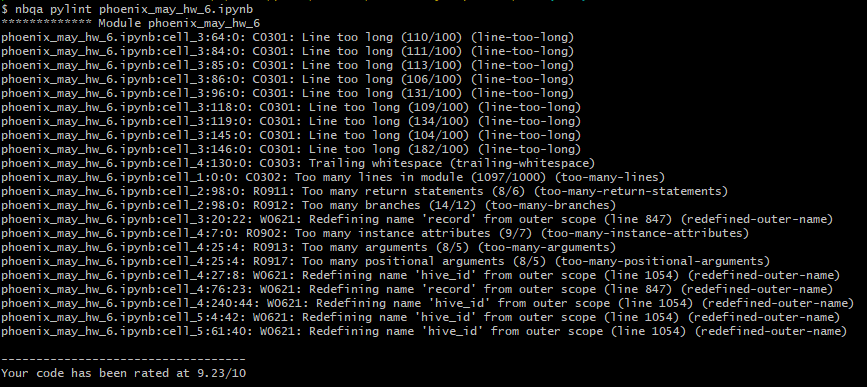